# Knowledge distillation no GraphPFN: student podado × student aleatório

**Pergunta:** ao destilar o GraphPFN completo em um modelo menor, começar de um **student podado** (pesos pré-treinados, camadas removidas) traz vantagem sobre começar de um **student aleatório** com a mesma arquitetura?

| Experimento | Teacher | Student | Inicialização do student |
|---|---|---|---|
| **1. KD → podado** | GraphPFN completo (12 camadas), congelado | 6 camadas | pesos do GraphPFN, sem as 6 camadas de menor BI cosseno (camada 0 protegida) |
| **2. KD → aleatório** | o mesmo | 6 camadas, mesma arquitetura e nº de parâmetros | aleatória (inicialização padrão da arquitetura, sem pré-treino) |

A poda escolhida (remover 6 camadas, −48% dos parâmetros) **derruba bastante o desempenho** sem re-treino (ver `poda_cosseno_artigo_graphpfn.ipynb`). A pergunta é se o KD recupera esse desempenho mais rápido e/ou melhor partindo do podado.

### O que é medido

| Pergunta | Medida |
|---|---|
| Qual converge mais rápido? | loss de KD na validação por passo e por tempo de parede |
| Chegam no mesmo mínimo? | menor loss de KD atingida por cada student |
| Diferença de tempo | **podado:** tempo da poda (BI + remoção) + tempo de KD até um nível de loss; **aleatório:** tempo de KD até o mesmo nível |
| Desempenho final | métrica do artigo (AP / acurácia / R²) no teste, com ensemble de 10 |

### Protocolo de KD

Segue o *finetuning* oficial do GraphPFN (`graphpfn.inference.finetune.predict_ft`, usado no artigo), trocando os rótulos pela saída do teacher:

- A cada passo, até 1024 nós de **treino** viram consulta e o resto do treino é contexto (≥ 75%). Nós de validação e teste nunca são usados no treino.
- Teacher e student recebem **exatamente a mesma entrada**: o mesmo membro de ensemble (permutação de features/classes) e as mesmas features aleatórias.
- **Loss de KD** (sem rótulos): classificação = $T^2 \cdot KL(p_T \,\|\, p_S)$ com temperatura $T = 2$; regressão = MSE entre as saídas (alvo padronizado). Assim, o mínimo teórico é 0 para os dois students.
- Otimizador Adam. A taxa de aprendizado é escolhida **separadamente para cada student** em uma varredura curta (mesma grade: 1e-4, 3e-4, 1e-3; 20 passos), pela loss de KD na validação, para não favorecer nenhum dos dois.
- 200 passos de KD por student, 1 semente. Em amazon-ratings e city-roads-M cada passo leva ~19 s na GPU de 16 GB (o grafo inteiro passa pelo modelo a cada passo, com *gradient checkpointing*).
- A curva de convergência usa a **loss de KD na validação**: student e teacher fazem inferência ICL com todo o treino como contexto, e a loss é medida nos nós de validação.

**Datasets:** um por tipo de tarefa, entre os que cabem para treino em 16 GB: tolokers-2 (binária), amazon-ratings (multiclasse) e city-roads-M (regressão), com o mesmo pré-processamento e split do artigo.

## 0. Configuração

In [1]:
import os, sys, json, time, random, warnings
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
from pathlib import Path
from unittest import mock

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / "src" / "graphpfn").exists() else cwd / "GraphFPN"
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.checkpoint
import dgl
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import accuracy_score, average_precision_score, r2_score
from IPython.display import display

import graphpfn.model.light as light_module
from graphpfn import GraphDataset, GraphPFN, GraphPFNLight
from graphpfn.model.limix import LimiXWrapper
from graphpfn.model.ensemble import apply_feature_transform, apply_target_transform
from graphpfn.inference.preprocessing import prepare_features_tensor, prepare_graph, standardize_targets
from graphpfn.inference.util import CandidateQueue

DEVICE = torch.device("cuda")
CHECKPOINT = PROJECT_ROOT / "checkpoints" / "graphpfn-adapters-1_3.pt"
GRAPHLAND_ROOT = Path.home() / ".cache" / "graphland"
PYG_ROOT = Path.home() / ".cache" / "pyg_data"
RESULTS_DIR = PROJECT_ROOT.parent / "Block_Influence_results" / "graphfpn_kd_podado_vs_aleatorio"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DATASETS = {
    "tolokers-2":     dict(source="graphland"),
    "amazon-ratings": dict(source="classic", d_pca=64),
    "city-roads-M":   dict(source="graphland"),
}
N_LAYERS = 12
PRUNE_K = 6                 # camadas removidas → student de 6 camadas
PROTECTED = {0}
SEED = 0

# KD (mesmos valores padrão de predict_ft)
TRAIN_BATCH = 1024
MIN_CONTEXT_RATIO = 0.75
TEMPERATURE = 2.0
N_STEPS = 200
EVAL_EVERY = 10
LR_GRID = [1e-4, 3e-4, 1e-3]
SWEEP_STEPS = 20
N_MEMBERS_FINAL = 10        # avaliação final com o ensemble do artigo
AMP = True

PRIMARY_METRIC = {"binclass": "AP", "multiclass": "Acurácia", "regression": "R²"}
STUDENTS = ["Podado", "Aleatório"]
COLORS = {"Podado": "#2a78d6", "Aleatório": "#eb6834"}
GRAY = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "lines.linewidth": 2, "lines.markersize": 4, "font.size": 10,
})
print(f"GPU: {torch.cuda.get_device_name()} | resultados: {RESULTS_DIR}")

GPU: NVIDIA GeForce RTX 5060 Ti | resultados: /home/isabelly/Documentos/Graph_Pruning/Block_Influence_results/graphfpn_kd_podado_vs_aleatorio


## 1. Inferência e treino em blocos (GPU de 16 GB)

Mesma técnica de `poda_cosseno_artigo_graphpfn.ipynb`: operações independentes por nó/token são feitas em blocos (resultado idêntico) e o `feature_decoder`, que só serve à perda auxiliar do pré-treino, é desligado. No treino, cada bloco e cada camada usam *gradient checkpointing* (recalculados no backward em vez de guardar ativações); sem isso o treino não cabe em 16 GB nem no tolokers-2.

In [2]:
import torch.utils.checkpoint
from graphpfn._vendor.limix.model.layer import MLP, MultiheadAttention
from graphpfn.model.layers import GraphPFNResidualModule
from graphpfn._vendor.limix.model.encoders import MaskEmbEncoder

CHUNK_BUDGET = 2**26  # elementos por bloco de computação


def _ck(fn, *args):
    """No treino (com gradiente), cada bloco é recalculado no backward em vez de guardar suas ativações."""
    if torch.is_grad_enabled():
        return torch.utils.checkpoint.checkpoint(fn, *args, use_reentrant=False)
    return fn(*args)


def _wrap_attention(orig):
    """Atenção de features ([1, nós, tokens, E]) e de amostras ([1, tokens, nós, E]): independente ao longo da dim 1."""
    def forward(x, x_kv=None, copy_first_head_kv=False, attn_mask=None,
                calculate_sample_attention=False, calculate_feature_attention=False):
        if attn_mask is not None or calculate_sample_attention or calculate_feature_attention:
            return orig(x, x_kv, copy_first_head_kv, attn_mask, calculate_sample_attention, calculate_feature_attention)
        per_slice = max(x.shape[2], x_kv.shape[2] if x_kv is not None else 0) * x.shape[3] * 4
        step = max(1, CHUNK_BUDGET // per_slice)
        att = lambda a, b: orig(a, b, copy_first_head_kv)[0]
        out = torch.cat([_ck(att, x[:, i:i + step], None if x_kv is None else x_kv[:, i:i + step])
                         for i in range(0, x.shape[1], step)], dim=1)
        return out, None, None
    return forward


def _wrap_mlp(orig, hidden):
    """MLP atua token a token."""
    def forward(x):
        flat = x.reshape(-1, x.shape[-1])
        step = max(1, CHUNK_BUDGET // hidden)
        return torch.cat([_ck(orig, flat[i:i + step]) for i in range(0, flat.shape[0], step)]).reshape(*x.shape[:-1], -1)
    return forward


def _wrap_graph_residual(orig):
    """Adaptadores de grafo (atenção nas arestas e MLP): independentes por posição de token."""
    def forward(graph, x):
        n_tokens = x.shape[2]
        per_token = max(graph.num_edges() * 4 * 3, x.shape[1] * x.shape[3] * 6)
        step = max(1, CHUNK_BUDGET // per_token)
        if step >= n_tokens:
            return _ck(lambda a: orig(graph, a), x)
        return torch.cat([_ck(lambda a: orig(graph, a), x[:, :, i:i + step].contiguous())
                          for i in range(0, n_tokens, step)], dim=2)
    return forward


def _wrap_feature_encoder(orig, out_key):
    """Encoder de features: cada valor vira um embedding sem olhar os outros nós."""
    def forward(inp):
        n = inp["data"].shape[1]
        step = max(1, CHUNK_BUDGET // (inp["data"].shape[2] * 192 * 6))
        keys = [k for k, v in inp.items() if torch.is_tensor(v) and v.ndim >= 2 and v.shape[1] == n]
        rest = {k: v for k, v in inp.items() if k not in keys}

        def run(*tensors):
            return orig({**rest, **dict(zip(keys, tensors))})[out_key]
        out = dict(inp)  # não altera o dicionário de entrada (o recálculo do checkpoint o reutiliza)
        out[out_key] = torch.cat([_ck(run, *[inp[k][:, i:i + step] for k in keys])
                                  for i in range(0, n, step)], dim=1)
        return out
    return forward


def enable_low_memory(model):
    """Processa em blocos as operações independentes por nó/token. Matematicamente idêntico ao forward original."""
    if getattr(model, "_low_memory", False):
        return model
    for m in model.modules():
        if isinstance(m, MultiheadAttention):
            m.forward = _wrap_attention(m.forward)
        elif isinstance(m, MLP):
            m.forward = _wrap_mlp(m.forward, m.mlp[0].out_features)
        elif isinstance(m, GraphPFNResidualModule):
            m.forward = _wrap_graph_residual(m.forward)
        elif isinstance(m, MaskEmbEncoder):
            m.forward = _wrap_feature_encoder(m.forward, m.out_key)
    # feature_decoder só alimenta a perda auxiliar de reconstrução de features (MGM, usada no pré-treino);
    # a predição sai de cls_y_decoder/reg_y_decoder. Na inferência ele é o pico de memória, então é desligado.
    model.tfm.module.feature_decoder.forward = lambda x: None
    model._low_memory = True
    return model

## 2. Dados

In [3]:
def random_split(n, seed=0):
    perm = np.random.default_rng(seed).permutation(n)
    a, b = int(0.1 * n), int(0.2 * n)
    masks = {k: np.zeros(n, bool) for k in ["train", "val", "test"]}
    masks["train"][perm[:a]] = True; masks["val"][perm[a:b]] = True; masks["test"][perm[b:]] = True
    return masks

def load_classic(name):
    from torch_geometric.datasets import HeterophilousGraphDataset
    g = HeterophilousGraphDataset(PYG_ROOT, name)[0]
    src, dst = g.edge_index.numpy()
    return GraphDataset(name=name, graph=dgl.graph((src, dst), num_nodes=g.num_nodes, idtype=torch.int32),
                        features={"other": g.x.numpy().astype(np.float32)}, targets=g.y.numpy().astype(np.float32),
                        masks=random_split(g.num_nodes),
                        task_type="binclass" if name == "questions" else "multiclass")

def prepare_task(name, cfg):
    if cfg["source"] == "graphland":
        ds = GraphDataset.from_graphland(name, root_dir=GRAPHLAND_ROOT / name / name / "raw", split="RL")
    else:
        ds = load_classic(name)
    graph = prepare_graph(ds.graph).to(DEVICE)
    np.random.seed(0)
    features = prepare_features_tensor(ds.features, ds.masks["train"], d_pca=cfg.get("d_pca")).to(DEVICE)
    train_mask = torch.tensor(ds.masks["train"]).to(DEVICE)
    y_train = torch.tensor(ds.targets).to(DEVICE)[train_mask]
    stats = None
    if ds.task_type == "regression":
        y_train, stats = standardize_targets(y_train=y_train)
    else:
        y_train = y_train.long()
    return dict(name=name, ds=ds, task=ds.task_type, graph=graph, features=features,
                train_mask=train_mask, y_train=y_train, stats=stats, n_classes=ds.n_classes)

## 3. Modelos: teacher, poda e student aleatório

- **Teacher:** GraphPFN completo, congelado.
- **Poda:** o BI cosseno de cada camada é medido com *hooks* em um forward do teacher nesse dataset. Depois, as 6 camadas de menor BI fora da camada 0 são removidas. **Esse tempo é o "tempo de poda"** somado ao tempo de KD do student podado.
- **Aleatório:** o mesmo GraphPFN montado sem carregar pesos (inicialização padrão do LimiX; os adaptadores de grafo começam zerados, como no GraphPFN), com as 6 primeiras camadas mantidas. A arquitetura e o número de parâmetros são iguais aos do podado.

In [4]:
def load_pretrained():
    base = GraphPFNLight()
    base.load_state_dict(torch.load(CHECKPOINT, map_location="cpu", weights_only=True)["state_dict"], strict=False)
    return base.to(DEVICE)

def load_random(seed):
    torch.manual_seed(seed)
    with mock.patch.object(light_module, "LimiXWrapper", lambda load_weights=True: LimiXWrapper(load_weights=False)):
        base = GraphPFNLight()
    return base.to(DEVICE)

def keep_layers(base, keep):
    stack = base.tfm.module.transformer_encoder
    stack.layers = nn.ModuleList([stack.layers[i] for i in keep])
    return base

def checkpoint_layers(base):
    """Gradient checkpointing por camada inteira durante o treino: guarda só a entrada de cada camada e
    recalcula a camada no backward. Mesmo resultado, muito menos memória. (O GraphPFN só liga o seu
    checkpointing interno para entradas com mais de 400 mil elementos, o que deixa de fora o tolokers-2.)"""
    def wrap(layer):
        orig = layer.forward
        holder = layer._graph_holder
        def forward(*a, **k):
            if not torch.is_grad_enabled():
                return orig(*a, **k)
            graph = holder.graph  # o GraphPFN limpa o grafo ao fim do forward; o recálculo precisa dele
            def run(*a2, **k2):
                saved, holder.graph = holder.graph, graph
                try:
                    return orig(*a2, **k2)
                finally:
                    holder.graph = saved
            return torch.utils.checkpoint.checkpoint(run, *a, use_reentrant=False, **k)
        layer.forward = forward
    for layer in base.tfm.module.transformer_encoder.layers:
        wrap(layer)
    return base

def n_params(m):
    return sum(p.numel() for p in m.parameters())

def raw_forward(base, t, member=None, context_mask=None, y_context=None, seed=0):
    """Forward do GraphPFNLight. Classificação: log-probabilidades; regressão: alvo padronizado."""
    feats = t["features"] if member is None else apply_feature_transform(t["features"], member)
    if context_mask is None:
        context_mask, y_context = t["train_mask"], t["y_train"]
    if member is not None:
        y_context = apply_target_transform(y_context, member)
    torch.manual_seed(seed)  # mesmas features aleatórias para teacher e student
    with torch.autocast("cuda", enabled=AMP, dtype=torch.bfloat16):
        return base(graph=t["graph"], features=feats, y_train=y_context, train_mask=context_mask,
                    task_type=t["task"]).float()

@torch.no_grad()
def measure_bi(base, t):
    """BI cosseno (todos os tokens) por camada, em um forward com o modelo completo."""
    acc = {}
    def hook(i):
        def h(m, a, kw, out):
            x, y = a[0][0], out[0][0]
            s = n = 0.0
            for c in range(0, x.shape[0], 4096):
                cos = F.cosine_similarity(x[c:c + 4096].float(), y[c:c + 4096].float(), dim=-1)
                s += (1 - cos).sum().item(); n += cos.numel()
            acc[i] = s / n
        return h
    hooks = [l.register_forward_hook(hook(i), with_kwargs=True)
             for i, l in enumerate(base.tfm.module.transformer_encoder.layers)]
    try:
        raw_forward(base, t)
    finally:
        for h in hooks:
            h.remove()
    return pd.Series(acc).sort_index()

### Loss de KD e avaliação

In [5]:
def kd_loss(s, t_out, task, n_classes):
    if task == "regression":
        return F.mse_loss(s, t_out)
    zs, zt = s[..., :n_classes] / TEMPERATURE, t_out[..., :n_classes] / TEMPERATURE
    return F.kl_div(F.log_softmax(zs, -1), F.log_softmax(zt, -1), log_target=True, reduction="batchmean") * TEMPERATURE ** 2

def task_metric(t, raw, split):
    m = t["ds"].masks[split]
    y = t["ds"].targets[m]
    p = raw[m]
    if t["task"] == "regression":
        return r2_score(y, float(t["stats"].mean) + float(t["stats"].std) * p)
    probs = np.exp(p[:, :t["n_classes"]])
    if t["task"] == "binclass":
        return average_precision_score(y, probs[:, 1] / probs.sum(1))
    return accuracy_score(y, probs.argmax(1))

@torch.no_grad()
def evaluate(base, t, teacher_raw):
    """Loss de KD (val/teste) contra o teacher e métrica do artigo, em ICL com todo o treino como contexto."""
    base.eval()
    raw = raw_forward(base, t, seed=SEED)
    out = {}
    for split in ["val", "test"]:
        m = torch.tensor(t["ds"].masks[split], device=DEVICE)
        out[f"kd_{split}"] = kd_loss(raw[m], teacher_raw[m], t["task"], t["n_classes"]).item()
        out[f"metric_{split}"] = task_metric(t, raw.cpu().numpy(), split)
    return out

@torch.no_grad()
def evaluate_ensemble(base, t, n_members=N_MEMBERS_FINAL):
    """Métrica no teste com o ensemble do artigo (10 membros)."""
    base.eval()
    torch.manual_seed(SEED)
    model = GraphPFN(base, n_members=n_members, n_features=t["features"].shape[1], n_classes=t["n_classes"],
                     device=DEVICE, verbose=False).eval()
    with torch.autocast("cuda", enabled=AMP, dtype=torch.bfloat16):
        p = model(graph=t["graph"], features=t["features"], y_train=t["y_train"],
                  train_mask=t["train_mask"], task_type=t["task"]).float()
    raw = p.cpu().numpy() if t["task"] == "regression" else p[:, :t["n_classes"]].cpu().numpy()
    return task_metric(t, raw, "test")

### Laço de KD

Cada passo: sorteia a consulta (como `predict_ft`), sorteia um membro do ensemble, roda o teacher (sem gradiente) e o student com a mesma entrada, e faz um passo de Adam na loss de KD. O tempo de KD conta só os passos de treino (avaliações periódicas são descontadas).

In [6]:
def kd_train(student, teacher, t, lr, n_steps, teacher_raw, label, eval_every=EVAL_EVERY):
    torch.manual_seed(SEED); random.seed(SEED)
    ens = GraphPFN(teacher, n_members=10, n_features=t["features"].shape[1], n_classes=t["n_classes"],
                   device=DEVICE, verbose=False).ensemble
    opt = torch.optim.Adam(student.parameters(), lr=lr)
    train_idx = t["train_mask"].nonzero().squeeze(1)
    n_train, n_nodes = len(train_idx), t["train_mask"].shape[0]
    queue = CandidateQueue(n_train, n_candidates=min(TRAIN_BATCH, int(n_train * (1 - MIN_CONTEXT_RATIO))), device=DEVICE)

    log = [dict(step=0, t_kd=0.0, train_loss=np.nan, **evaluate(student, t, teacher_raw))]
    t_kd, losses = 0.0, []
    for step in range(1, n_steps + 1):
        torch.cuda.synchronize(); tic = time.time()
        student.train()
        q = next(queue)
        query = torch.zeros(n_train, dtype=torch.bool, device=DEVICE); query[q] = True
        ctx_nodes = torch.zeros(n_nodes, dtype=torch.bool, device=DEVICE); ctx_nodes[train_idx[~query]] = True
        q_nodes = torch.zeros(n_nodes, dtype=torch.bool, device=DEVICE); q_nodes[train_idx[query]] = True
        _, member = ens.sample_member()
        y_ctx = t["y_train"][~query]
        with torch.no_grad():
            t_out = raw_forward(teacher, t, member, ctx_nodes, y_ctx, seed=SEED * 100_000 + step)[q_nodes]
        s_out = raw_forward(student, t, member, ctx_nodes, y_ctx, seed=SEED * 100_000 + step)[q_nodes]
        loss = kd_loss(s_out, t_out, t["task"], t["n_classes"])
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        torch.cuda.synchronize(); t_kd += time.time() - tic
        losses.append(loss.item())
        if not np.isfinite(losses[-1]):
            print(f"  {label}: loss não finita no passo {step}, interrompido")
            break
        if step % eval_every == 0 or step == n_steps:
            log.append(dict(step=step, t_kd=t_kd, train_loss=float(np.mean(losses[-eval_every:])),
                            **evaluate(student, t, teacher_raw)))
    return pd.DataFrame(log)

## 4. Execução

Para cada dataset:
1. teacher: predições de referência e métrica;
2. **poda** (cronometrada): BI + remoção das camadas;
3. varredura curta de taxa de aprendizado para cada student (20 passos, mesma grade);
4. KD completo (200 passos) de cada student com a sua melhor taxa;
5. avaliação final com ensemble de 10.

Os logs são salvos por dataset; execuções já feitas são carregadas do disco.

In [7]:
def build_student(kind, t, teacher):
    """Devolve (student, tempo_de_poda_s, camadas_mantidas)."""
    if kind == "Podado":
        torch.cuda.synchronize(); tic = time.time()
        bi = measure_bi(teacher, t)
        removed = [l for l in bi.sort_values().index if l not in PROTECTED][:PRUNE_K]
        keep = [i for i in range(N_LAYERS) if i not in removed]
        student = keep_layers(load_pretrained(), keep)
        torch.cuda.synchronize()
        return checkpoint_layers(enable_low_memory(student)), time.time() - tic, keep
    keep = list(range(N_LAYERS - PRUNE_K))
    return checkpoint_layers(enable_low_memory(keep_layers(load_random(SEED), keep))), 0.0, keep

SUMMARY = []
for name, cfg in DATASETS.items():
    out_log = RESULTS_DIR / f"kd_log_{name}.csv"
    out_sum = RESULTS_DIR / f"kd_resumo_{name}.json"
    if out_log.exists() and out_sum.exists():
        print(f"(carregado do cache: {name})")
        SUMMARY.append(json.load(open(out_sum)))
        continue
    t = prepare_task(name, cfg)
    teacher = enable_low_memory(load_pretrained()).eval()
    for p in teacher.parameters():
        p.requires_grad_(False)
    with torch.no_grad():
        teacher_raw = raw_forward(teacher, t, seed=SEED)
    info = dict(dataset=name, task=t["task"], metric=PRIMARY_METRIC[t["task"]],
                teacher_metric_test=task_metric(t, teacher_raw.cpu().numpy(), "test"),
                teacher_metric_test_ens=evaluate_ensemble(teacher, t),
                params_teacher=n_params(teacher))
    logs = []
    for kind in STUDENTS:
        # varredura de lr
        sweep = {}
        for lr in LR_GRID:
            st, t_prune, keep = build_student(kind, t, teacher)
            try:
                d = kd_train(st, teacher, t, lr, SWEEP_STEPS, teacher_raw, f"{kind} lr={lr:g}", eval_every=SWEEP_STEPS)
                sweep[lr] = d["kd_val"].iloc[-1] if np.isfinite(d["kd_val"].iloc[-1]) else np.inf
            except torch.OutOfMemoryError:
                sweep[lr] = np.inf
            del st; torch.cuda.empty_cache()
        best_lr = min(sweep, key=sweep.get)
        print(f"{name} | {kind}: loss de KD (val) após {SWEEP_STEPS} passos por lr = "
              f"{ {f'{k:g}': round(v, 4) for k, v in sweep.items()} } → lr = {best_lr:g}")
        # KD completo
        st, t_prune, keep = build_student(kind, t, teacher)
        info[f"metric_test_ens_antes_{kind}"] = evaluate_ensemble(st, t)
        d = kd_train(st, teacher, t, best_lr, N_STEPS, teacher_raw, kind)
        info[f"metric_test_ens_depois_{kind}"] = evaluate_ensemble(st, t)
        info.update({f"lr_{kind}": best_lr, f"t_poda_{kind}": t_prune, f"camadas_{kind}": keep,
                     f"params_{kind}": n_params(st), f"sweep_{kind}": {f"{k:g}": v for k, v in sweep.items()}})
        logs.append(d.assign(dataset=name, student=kind, lr=best_lr, t_poda=t_prune))
        del st; torch.cuda.empty_cache()
    pd.concat(logs).to_csv(out_log, index=False)
    json.dump(info, open(out_sum, "w"), default=float, indent=1)
    SUMMARY.append(info)
    del teacher, teacher_raw, t; torch.cuda.empty_cache()

LOG = pd.concat([pd.read_csv(RESULTS_DIR / f"kd_log_{n}.csv") for n in DATASETS])

tolokers-2 | Podado: loss de KD (val) após 20 passos por lr = {'0.0001': np.float64(0.1373), '0.0003': np.float64(0.3093), '0.001': np.float64(0.3101)} → lr = 0.0001


tolokers-2 | Aleatório: loss de KD (val) após 20 passos por lr = {'0.0001': np.float64(0.2946), '0.0003': np.float64(0.3146), '0.001': np.float64(0.3128)} → lr = 0.0001


amazon-ratings | Podado: loss de KD (val) após 20 passos por lr = {'0.0001': np.float64(0.3009), '0.0003': np.float64(0.2925), '0.001': np.float64(0.6904)} → lr = 0.0003


amazon-ratings | Aleatório: loss de KD (val) após 20 passos por lr = {'0.0001': np.float64(0.6672), '0.0003': np.float64(0.6767), '0.001': np.float64(0.567)} → lr = 0.001


city-roads-M | Podado: loss de KD (val) após 20 passos por lr = {'0.0001': np.float64(0.1404), '0.0003': np.float64(0.2661), '0.001': np.float64(0.6621)} → lr = 0.0001


city-roads-M | Aleatório: loss de KD (val) após 20 passos por lr = {'0.0001': np.float64(0.6727), '0.0003': np.float64(0.715), '0.001': np.float64(0.6692)} → lr = 0.001


## 5. Convergência da loss de KD

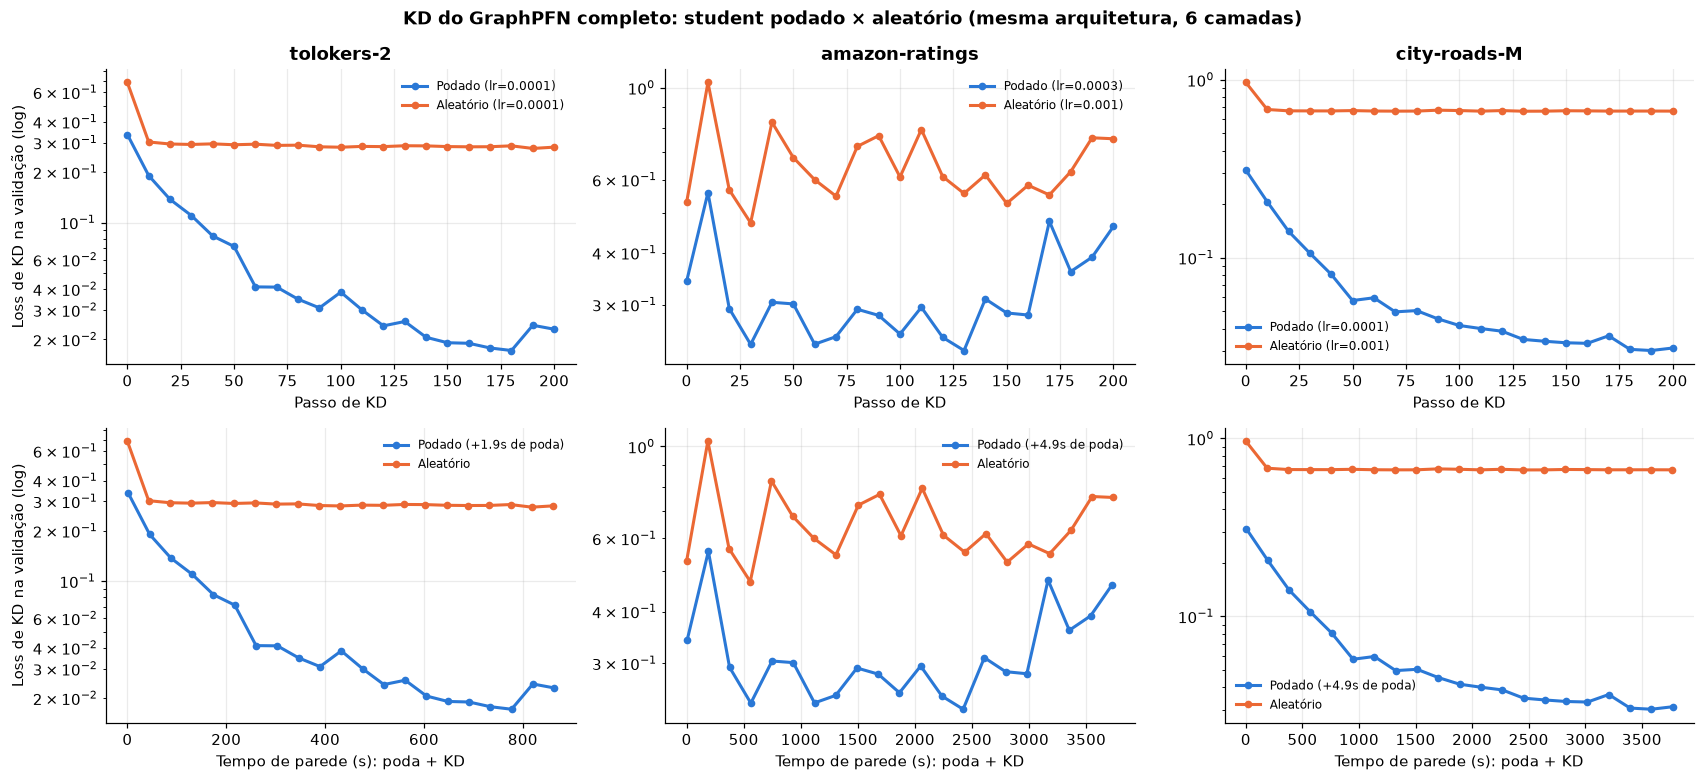

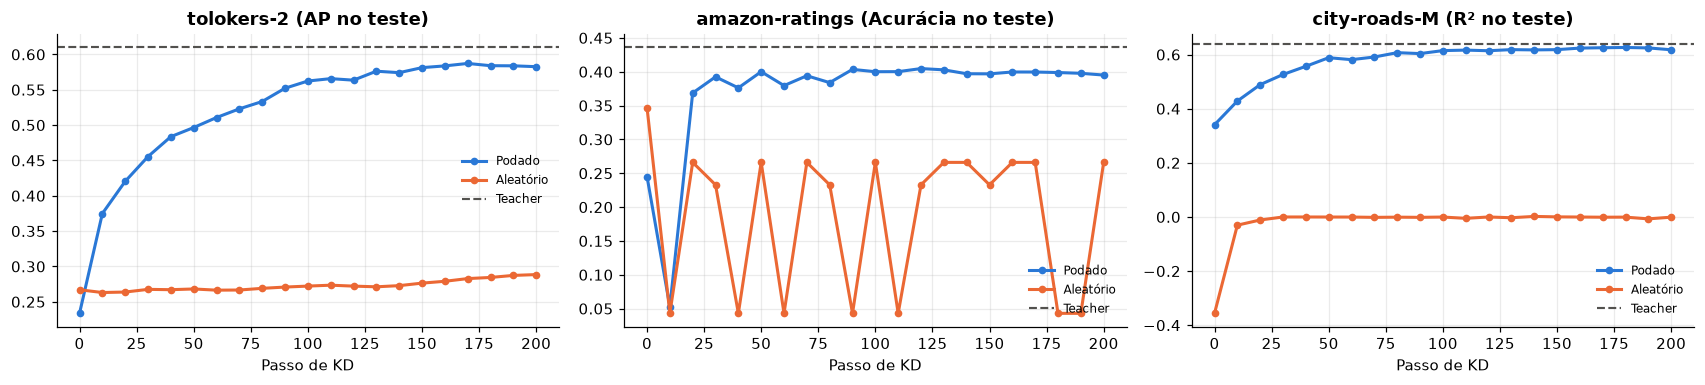

In [8]:
fig, axes = plt.subplots(2, len(DATASETS), figsize=(5.2 * len(DATASETS), 7.2), squeeze=False)
for j, name in enumerate(DATASETS):
    for kind in STUDENTS:
        d = LOG[(LOG.dataset == name) & (LOG.student == kind)]
        axes[0, j].plot(d.step, d.kd_val, marker="o", color=COLORS[kind], label=f"{kind} (lr={d.lr.iloc[0]:g})")
        axes[1, j].plot(d.t_poda + d.t_kd, d.kd_val, marker="o", color=COLORS[kind],
                        label=f"{kind}" + (f" (+{d.t_poda.iloc[0]:.1f}s de poda)" if kind == "Podado" else ""))
    for ax in axes[:, j]:
        ax.set_yscale("log")
        ax.legend(frameon=False, fontsize=8)
    axes[0, j].set_title(name)
    axes[0, j].set_xlabel("Passo de KD")
    axes[1, j].set_xlabel("Tempo de parede (s): poda + KD")
axes[0, 0].set_ylabel("Loss de KD na validação (log)")
axes[1, 0].set_ylabel("Loss de KD na validação (log)")
fig.suptitle("KD do GraphPFN completo: student podado × aleatório (mesma arquitetura, 6 camadas)", fontweight="bold")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "kd_convergencia.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.2 * len(DATASETS), 3.6), squeeze=False)
for j, (name, info) in enumerate(zip(DATASETS, SUMMARY)):
    ax = axes[0, j]
    for kind in STUDENTS:
        d = LOG[(LOG.dataset == name) & (LOG.student == kind)]
        ax.plot(d.step, d.metric_test, marker="o", color=COLORS[kind], label=kind)
    ax.axhline(info["teacher_metric_test"], color=GRAY, ls="--", lw=1.4, label="Teacher")
    ax.set_title(f"{name} ({info['metric']} no teste)")
    ax.set_xlabel("Passo de KD")
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "kd_metrica.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Mínimo, velocidade de convergência e tempo

- **Mínimo:** menor loss de KD na validação de cada student.
- **Nível comum:** o maior dos dois mínimos, ou seja, o menor nível de loss que **os dois** atingem. Para cada student, mede-se o primeiro instante em que a loss fica ≤ esse nível.
- **Tempo total:** podado = poda + KD até o nível comum; aleatório = KD até o nível comum.
- **Passos até 90% da queda:** passos até a loss cair 90% do caminho entre o valor inicial e o mínimo do próprio student.

In [9]:
rows = []
for name, info in zip(DATASETS, SUMMARY):
    d = {k: LOG[(LOG.dataset == name) & (LOG.student == k)].reset_index(drop=True) for k in STUDENTS}
    level = max(d[k].kd_val.min() for k in STUDENTS)
    for k in STUDENTS:
        x = d[k]
        hit = x[x.kd_val <= level * 1.0001].iloc[0]
        drop90 = x.kd_val.iloc[0] - 0.9 * (x.kd_val.iloc[0] - x.kd_val.min())
        rows.append({
            "dataset": name, "student": k, "lr": info[f"lr_{k}"],
            "loss KD inicial": x.kd_val.iloc[0], "loss KD mínima": x.kd_val.min(),
            "loss KD final": x.kd_val.iloc[-1],
            "nível comum": level, "passos até o nível": int(hit.step),
            "tempo de poda (s)": info[f"t_poda_{k}"], "tempo de KD até o nível (s)": hit.t_kd,
            "tempo total até o nível (s)": info[f"t_poda_{k}"] + hit.t_kd,
            "passos até 90% da queda": int(x[x.kd_val <= drop90].iloc[0].step),
            "tempo médio por passo (s)": x.t_kd.iloc[-1] / max(x.step.iloc[-1], 1),
        })
conv = pd.DataFrame(rows)
conv.to_csv(RESULTS_DIR / "kd_convergencia.csv", index=False)
display(conv.style.format({c: "{:.4f}" for c in ["loss KD inicial", "loss KD mínima", "loss KD final", "nível comum"]}
                          | {c: "{:.1f}" for c in conv.columns if "(s)" in c} | {"lr": "{:g}"})
        .hide(axis="index").set_caption("Convergência e tempo"))

perf = pd.DataFrame([{
    "dataset": info["dataset"], "métrica": info["metric"],
    "Teacher (12 camadas)": info["teacher_metric_test_ens"],
    "Podado antes do KD": info["metric_test_ens_antes_Podado"],
    "Podado após KD": info["metric_test_ens_depois_Podado"],
    "Aleatório antes do KD": info["metric_test_ens_antes_Aleatório"],
    "Aleatório após KD": info["metric_test_ens_depois_Aleatório"],
} for info in SUMMARY])
perf.to_csv(RESULTS_DIR / "kd_desempenho_final.csv", index=False)
display(perf.style.format({c: "{:.4f}" for c in perf.columns[2:]}).hide(axis="index")
        .set_caption(f"Métrica do artigo no teste, ensemble de {N_MEMBERS_FINAL} membros"))
print("Parâmetros:", {k: f"{SUMMARY[0][f'params_{k}'] / 1e6:.2f} M" for k in STUDENTS},
      f"| teacher: {SUMMARY[0]['params_teacher'] / 1e6:.2f} M")

dataset,student,lr,loss KD inicial,loss KD mínima,loss KD final,nível comum,passos até o nível,tempo de poda (s),tempo de KD até o nível (s),tempo total até o nível (s),passos até 90% da queda,tempo médio por passo (s)
tolokers-2,Podado,0.0001,0.3356,0.0172,0.0230,0.2771,10,1.9,43.1,45.0,60,4.3
tolokers-2,Aleatório,0.0001,0.6872,0.2771,0.2822,0.2771,190,0.0,818.2,818.2,10,4.3
amazon-ratings,Podado,0.0003,0.3415,0.2326,0.4630,0.4725,0,4.9,0.0,4.9,30,18.6
amazon-ratings,Aleatório,0.001,0.5293,0.4725,0.7534,0.4725,30,0.0,557.6,557.6,30,18.7
city-roads-M,Podado,0.0001,0.3106,0.0301,0.0311,0.6657,0,4.9,0.0,4.9,50,18.8
city-roads-M,Aleatório,0.001,0.9656,0.6657,0.6666,0.6657,130,0.0,2447.7,2447.7,10,18.8


dataset,métrica,Teacher (12 camadas),Podado antes do KD,Podado após KD,Aleatório antes do KD,Aleatório após KD
tolokers-2,AP,0.6094,0.3450,0.5859,0.2729,0.3040
amazon-ratings,Acurácia,0.4391,0.3686,0.4184,0.0769,0.3686
city-roads-M,R²,0.6489,0.4311,0.6237,-0.3154,-0.0008


Parâmetros: {'Podado': '10.35 M', 'Aleatório': '10.35 M'} | teacher: 20.09 M


## 7. Conclusões

Execução com 1 semente, 200 passos de KD por student, students de 6 camadas (10,35 M parâmetros, −48% do teacher de 20,09 M).

### Desempenho no teste (métrica do artigo, ensemble de 10)

| Dataset | Teacher | Podado antes do KD | **Podado após KD** | Aleatório antes do KD | Aleatório após KD |
|---|---|---|---|---|---|
| tolokers-2 (AP) | 0,609 | 0,345 | **0,586** | 0,273 | 0,304 |
| amazon-ratings (Acurácia) | 0,439 | 0,369 | **0,418** | 0,077 | 0,369 |
| city-roads-M (R²) | 0,649 | 0,431 | **0,624** | −0,315 | −0,001 |

### Loss de KD na validação e tempo

| Dataset | Student | lr | Loss inicial | **Loss mínima** | Nível comum | Tempo até o nível comum |
|---|---|---|---|---|---|---|
| tolokers-2 | Podado | 1e-4 | 0,336 | **0,017** | 0,277 | 1,9 s poda + 43 s KD = **45 s** |
| tolokers-2 | Aleatório | 1e-4 | 0,687 | 0,277 | 0,277 | 818 s |
| amazon-ratings | Podado | 3e-4 | 0,341 | **0,233** | 0,472 | 4,9 s poda + 0 s KD = **4,9 s** |
| amazon-ratings | Aleatório | 1e-3 | 0,529 | 0,472 | 0,472 | 558 s |
| city-roads-M | Podado | 1e-4 | 0,311 | **0,030** | 0,666 | 4,9 s poda + 0 s KD = **4,9 s** |
| city-roads-M | Aleatório | 1e-3 | 0,966 | 0,666 | 0,666 | 2.448 s |

"Nível comum" = o menor nível de loss que os dois students atingem (o mínimo do aleatório).

### Respostas

1. **O KD com o student podado tem vantagem clara, nos 3 datasets.** O podado recupera a maior parte do que a poda tirou: 96% do AP do teacher no tolokers-2, 95% da acurácia no amazon-ratings e 96% do R² no city-roads-M. O aleatório, com a mesma arquitetura, o mesmo número de parâmetros e o mesmo orçamento, termina no nível de um preditor constante: R² ≈ 0 no city-roads-M; no amazon-ratings a acurácia oscila entre 0,04, 0,23 e 0,27, isto é, prever sempre uma mesma classe.
2. **As losses não chegam no mesmo mínimo.** O mínimo do aleatório é 16× maior no tolokers-2, 2× no amazon-ratings e 22× no city-roads-M. A curva do aleatório fica plana desde o passo ~10 (cai rápido até a solução trivial e para), enquanto a do podado continua descendo até o fim no tolokers-2 e no city-roads-M.
3. **Convergência:** o podado já começa abaixo do mínimo que o aleatório alcança no amazon-ratings e no city-roads-M (por isso "0 s de KD" até o nível comum). Mesmo contando o tempo de poda, ele chega ao nível comum **18× a 500× mais rápido**.
4. **O custo da poda é desprezível:** 2–5 s (um forward com *hooks* para medir o BI + remover camadas), menos que o tempo de um único passo de KD nos datasets maiores (~19 s). O tempo por passo de KD é idêntico nos dois students (mesma arquitetura): 4,3 s no tolokers-2 e ~19 s no amazon-ratings e no city-roads-M.
5. **"Passos até 90% da queda" engana para o aleatório** (10 passos): ele cai rápido, mas para uma loss alta, a da solução constante. O que importa é o nível atingido.

### Ressalvas

- **amazon-ratings, podado:** a loss de validação é instável e volta a subir depois do passo ~130 (0,23 → 0,46), enquanto a de treino continua caindo (0,17): sobreajuste aos nós de treino com lr 3e-4. Guardar o melhor checkpoint pela loss de validação (como faz o `predict_ft` oficial) melhoraria o resultado final do podado; aqui é reportado o último passo.
- **O aleatório não teve chance justa de aprender ICL.** O GraphPFN é um modelo de aprendizado em contexto pré-treinado em milhões de datasets sintéticos. Um student aleatório destilado em um único dataset por 200 passos não aprende o mecanismo de usar os rótulos do contexto, por isso colapsa numa saída constante. Com muito mais passos ele poderia sair do platô, mas a curva plana não indica isso.
- 1 semente e 200 passos, por custo (~19 s por passo na GPU de 16 GB nos datasets maiores).

**Resumo:** para comprimir o GraphPFN por KD, partir do modelo podado é muito melhor do que partir do zero. A poda custa segundos, já começa mais perto do teacher e o KD recupera ~95% do desempenho em 200 passos. O student aleatório do mesmo tamanho fica preso numa solução constante.
